## Code to check configurations of points 

given four points $u,v,w,x$ in the plane we want to know when we can separate $u,v,w$ and $x$ by a line $L$ of positive slope such that either  

- $x$ pushes up and $u,v,w$ push right 
- $x$ pushes right and $u,v,w$ push up 

In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan
# plotting library for linear inequalities
#from intvalpy import lineqs
from scipy.spatial import HalfspaceIntersection, ConvexHull
# from scipy.optimize import linprog

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog


import sys 
sys.path.append('../Code/')
import modules as mod

# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

In [2]:
# here we define four critical values to check. 
# later we'll want to import these 4 at a time from a bigger set, but for now we just hardcode them.
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((0,1), 0)
c3 = mod.critical_val((1,0),0)
c4 = mod.critical_val((1,1),0)
CritPts = [c1,c2,c4]


In [105]:
def in_hull_mod(points, x):
    ## check if x in convex hull of points 
    ## points = array of pts in R^2 
    n_points = len(points)
    c = np.zeros(n_points)
    A = np.r_[points.T,np.ones((1,n_points))]
    b = np.r_[x, np.ones(1)]
    lp = linprog(c, A_eq=A, b_eq=b)
    return lp.success



[1 0] [1 0]
[0 0] [1 0]
[0 1] [1 1]


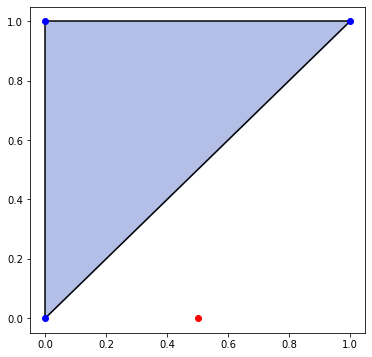

In [104]:
points = []
for c in CritPts:
    points.append(c.coords)
pointsnp = np.array(points)
x = (0.5,0)
in_hull_mod(pointsnp, x)
# print(points, "\n", pointsnp)

hull = scipy.spatial.ConvexHull(pointsnp)

# import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (6,6)
for simplex in hull.simplices:
    plt.plot(pointsnp[simplex, 0], pointsnp[simplex, 1], 'k-')
    print(pointsnp[simplex, 0], pointsnp[simplex, 1])
plt.fill(pointsnp[:,0],pointsnp[:,1], color=(.7,.75,.9), alpha = 1)
plt.plot(pointsnp[:,0], pointsnp[:,1], 'ob')
plt.plot(x[0], x[1], 'or')

[ True  True  True False  True False  True  True False False False  True
  True False False False False  True False False]


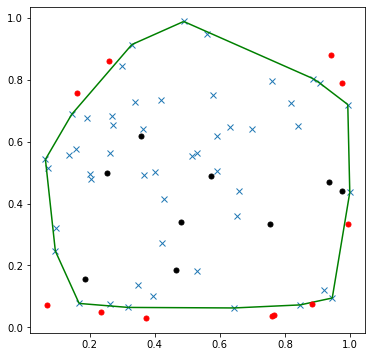

In [119]:
def in_hull(p, hull):
    """
    Test if points in `p` are in `hull`

    `p` should be a `NxK` coordinates of `N` points in `K` dimensions
    `hull` is either a scipy.spatial.Delaunay object or the `MxK` array of the 
    coordinates of `M` points in `K`dimensions for which Delaunay triangulation
    will be computed
    """
    from scipy.spatial import Delaunay
    if not isinstance(hull,Delaunay):
        hull = Delaunay(hull)

    return hull.find_simplex(p)>=0

def plot_in_hull(p, hull):
    """
    plot relative to `in_hull` for 2d data
    """
    import matplotlib.pyplot as plt
    from matplotlib.collections import PolyCollection, LineCollection

    from scipy.spatial import Delaunay
    if not isinstance(hull,Delaunay):
        hull = Delaunay(hull)

    # plot triangulation
    poly = PolyCollection(hull.points[hull.vertices], facecolors='w', edgecolors='b')
#     plt.clf()
#     plt.title('in hull')
#     plt.gca().add_collection(poly)
#     plt.plot(hull.points[:,0], hull.points[:,1], 'o', hold=1)
    plt.plot(hull.points[:,0], hull.points[:,1], 'x')


    # plot the convex hull
    edges = set()
    edge_points = []

    def add_edge(i, j):
        """Add a line between the i-th and j-th points, if not in the list already"""
        if (i, j) in edges or (j, i) in edges:
            # already added
            return
        edges.add( (i, j) )
        edge_points.append(hull.points[ [i, j] ])

    for ia, ib in hull.convex_hull:
        add_edge(ia, ib)

    lines = LineCollection(edge_points, color='g')
    plt.gca().add_collection(lines)
#     plt.show()    

    # plot tested points `p` - black are inside hull, red outside
    inside = in_hull(p,hull)
    plt.plot(p[ inside,0],p[ inside,1],'.k', markersize = 10)
    plt.plot(p[~inside,0],p[~inside,1],'.r', markersize = 10)

tested = np.random.rand(20,2)
cloud  = np.random.rand(50,2)

print(in_hull(tested,cloud))

plot_in_hull(tested,cloud)